In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout


In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Normalize and reshape
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

image_index = 0

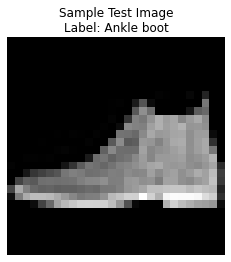

In [3]:
plt.figure(figsize=(4, 4))
plt.imshow(x_test[image_index].reshape(28, 28), cmap='gray')
plt.title(f"Sample Test Image\nLabel: {class_names[y_test[image_index]]}")
plt.axis('off')
plt.show()


In [4]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1), name='conv1'),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation='relu', name='conv2'),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    x_train, y_train, 
    epochs=5, 
    validation_data=(x_test, y_test)
)


Epoch 1/5
1875/1875 [==============================] - 28s 12ms/step - loss: 0.5612 - accuracy: 0.7996 - val_loss: 0.3608 - val_accuracy: 0.8686
Epoch 2/5
1875/1875 [==============================] - 23s 12ms/step - loss: 0.3721 - accuracy: 0.8686 - val_loss: 0.3234 - val_accuracy: 0.8820
Epoch 3/5
1875/1875 [==============================] - 20s 11ms/step - loss: 0.3225 - accuracy: 0.8852 - val_loss: 0.2949 - val_accuracy: 0.8929
Epoch 4/5
1875/1875 [==============================] - 20s 11ms/step - loss: 0.2944 - accuracy: 0.8939 - val_loss: 0.2727 - val_accuracy: 0.9001
Epoch 5/5
1875/1875 [==============================] - 20s 10ms/step - loss: 0.2714 - accuracy: 0.9020 - val_loss: 0.2654 - val_accuracy: 0.9022


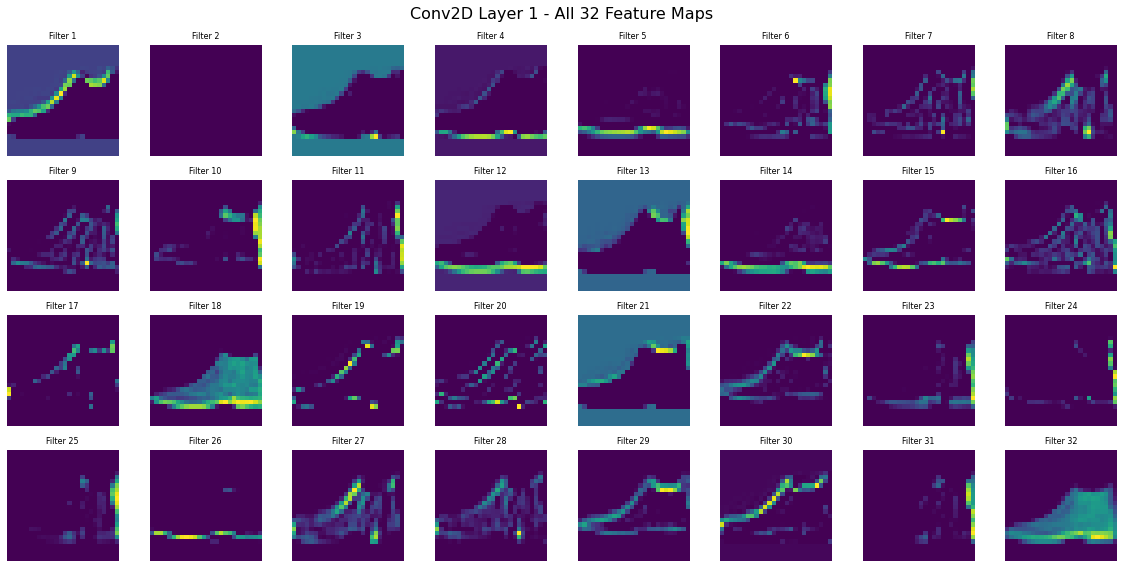

In [5]:
# Create a feature extractor model targeting 'conv1'
feature_model = Model(inputs=model.input, outputs=model.get_layer('conv1').output)

sample_image = x_test[image_index:image_index + 1]
conv1_output = feature_model.predict(sample_image)

# Plot all 32 feature maps in a 4x8 grid
plt.figure(figsize=(16, 8))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(conv1_output[0, :, :, i], cmap='viridis')
    plt.title(f"Filter {i + 1}", fontsize=8)
    plt.axis('off')

plt.suptitle("Conv2D Layer 1 - All 32 Feature Maps", fontsize=16)
plt.tight_layout()
plt.show()


Actual Class    : Ankle boot
Predicted Class : Ankle boot


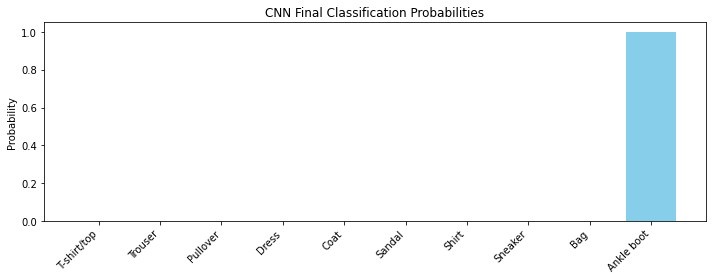

In [6]:
prediction = model.predict(sample_image)
predicted_class = np.argmax(prediction)

print(f"\nActual Class    : {class_names[y_test[image_index]]}")
print(f"Predicted Class : {class_names[predicted_class]}")

plt.figure(figsize=(10, 4))
plt.bar(class_names, prediction[0], color='skyblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel("Probability")
plt.title("CNN Final Classification Probabilities")
plt.tight_layout()
plt.show()


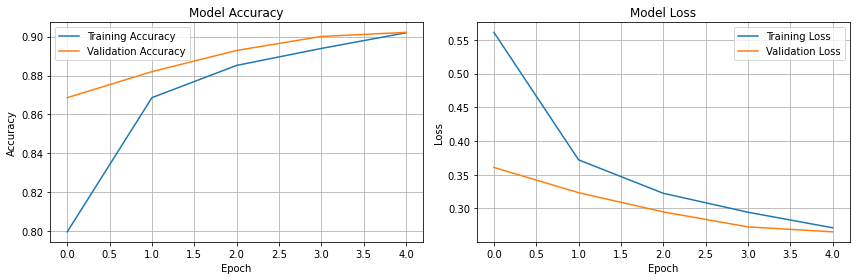

In [7]:
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [5]:
import os
os.makedirs("layer_outputs", exist_ok=True)

# One model that returns the output of EVERY layer
activation_model = Model(inputs=model.inputs,
                         outputs=[layer.output for layer in model.layers])

sample_image = x_test[image_index:image_index + 1]
activations = activation_model.predict(sample_image, verbose=0)

# Summary table: what happens to the data at each layer
print(f"{'Layer':<18}{'Type':<16}{'Output shape':<18}{'Params':<10}{'min':>8}{'max':>8}{'mean':>8}")
print("-" * 86)
print(f"{'input':<18}{'Input':<16}{str(sample_image.shape):<18}{0:<10}"
      f"{sample_image.min():>8.2f}{sample_image.max():>8.2f}{sample_image.mean():>8.2f}")
for layer, act in zip(model.layers, activations):
    print(f"{layer.name:<18}{type(layer).__name__:<16}{str(act.shape):<18}{layer.count_params():<10}"
          f"{act.min():>8.2f}{act.max():>8.2f}{act.mean():>8.2f}")

NameError: name 'model' is not defined